# Lab 8: full-field cavity learning across Reynolds number

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab8_High_Re_Field_DeepONet.ipynb)

Predict complete velocity fields and inspect their physical discrepancies.
This new companion follows Lab 7. Earlier notebooks and the historical
Ghia-profile MLP are preserved. Run All audits saved models on CPU; it does not
start training or HPC jobs.

[Protocol](../../docs/CAVITY_FIELD_NEURAL_PROTOCOL.md) |
[Results](../../results/cavity_field_deeponet/README.md) |
[CFD audit](../../results/cavity_highre_ghia/README.md) |
[Related studies](../../docs/CAVITY_ALL_RE_NEURAL_LITERATURE.md)

## 1. What is being learned?

The target is our steady 2-D square-cavity velocity on a 513-by-513 grid,
with a constant moving lid and its corner discontinuity. This is a specified
numerical solution, not an exact mesh-independent field. Pressure is not predicted.

Ghia supplies sparse centreline observations, used here only for comparison.
Training labels are our full CFD fields. A branch maps a scalar Re to coefficients
of a fixed POD trunk. This restricted POD-DeepONet is not a data-free PINN or
an operator over arbitrary boundary functions. Every location of each held-out
Re stays outside fitting and model selection.

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

import json
from flowmllab import cavity_field_operator as op
from flowmllab import cavity_field_evidence as evidence
OUT = ROOT/'results/cavity_field_deeponet'
selection = json.loads((OUT/'frozen_selection.json').read_text())
display(pd.DataFrame([
    {'Role':'Training','Re':selection['train_re']},
    {'Role':'Validation','Re':selection['validation_re']},
    {'Role':'Test','Re':selection['test_re']}]))
assert not set(selection['train_re']) & set(selection['test_re'])
assert not set(selection['validation_re']) & set(selection['test_re'])
print('Selected:',selection['selected_configuration'],'POD rank:',selection['rank'])
cases, info = evidence.load(ROOT)

Selected: hybrid_2 POD rank: 10


,Role,Re
0,Training,"[100, 250, 500, 750, 1000, 2500, 4000, 5000, 6..."
1,Validation,"[400, 6500]"
2,Test,"[3200, 7500]"


## 2. Spatial representation, architecture and optimization

Stack both velocity components into $\mathbf q=[u_1,\ldots,u_N,v_1,\ldots,v_N]^T$.
The training mean $\overline{\mathbf q}$ and orthonormal POD modes form the trunk:

$$\widehat{\mathbf q}(Re)=\overline{\mathbf q}
 +\sum_{k=1}^{r}a_k(Re)\boldsymbol\phi_k,\qquad
 \mathbf a(Re)=\mathbf s\odot f_\theta(\log_{10}Re-3).$$

Here $N=513^2$, $r$ is the training-only rank, $\theta$ the tanh branch parameters,
and $\mathbf s$ a training-only coefficient scale. The training loss is

$$J(\theta)=\frac{1}{n_{\rm tr}r}\sum_{j=1}^{n_{\rm tr}}\sum_{k=1}^{r}
 [f_{\theta,k}(z_j)-a_{jk}/s_k]^2.$$

Global scaling uses one RMS for all coefficients. Per-mode scaling uses each
mode's RMS, emphasizing low-energy structures. This can improve details or
harm generalization; it is a hypothesis to test.

Adam adapts updates using gradient moments. L-BFGS approximates curvature from
recent parameter and gradient changes. The hybrid warms up with Adam then
refines one fixed full-batch objective. Line-search evaluations count toward
the same budget. Five layers do not automatically outperform two.

In [2]:
validation = pd.read_csv(OUT/'validation_scores.csv')
display(validation[['method','seed','Re','relative_l2','parameters','evaluations']])
display(validation.groupby(['method','Re'],sort=False).relative_l2.agg(['mean','min','max']))
display(pd.read_csv(OUT/'validation_baselines.csv'))

,method,seed,Re,relative_l2,parameters,evaluations
0,adam_2,7,400,0.005708,1450,4000
1,adam_2,7,6500,0.002582,1450,4000
2,adam_2,23,400,0.005873,1450,4000
3,adam_2,23,6500,0.002065,1450,4000
4,adam_2,61,400,0.005163,1450,4000
5,adam_2,61,6500,0.002392,1450,4000
6,hybrid_2,7,400,0.005466,1450,4000
7,hybrid_2,7,6500,0.000355,1450,4000
8,hybrid_2,23,400,0.003168,1450,4000
9,hybrid_2,23,6500,0.000238,1450,4000


mean       min       max
method                    Re                                
adam_2                    400   0.005581  0.005163  0.005873
                          6500  0.002346  0.002065  0.002582
hybrid_2                  400   0.004147  0.003168  0.005466
                          6500  0.000315  0.000238  0.000355
hybrid_5                  400   0.005555  0.003595  0.006772
                          6500  0.000212  0.000183  0.000229
hybrid_5_balanced         400   0.023839  0.015079  0.034741
                          6500  0.015978  0.011481  0.021312
hybrid_5_capacity_matched 400   0.040744  0.035017  0.043646
                          6500  0.026069  0.017912  0.037751

,method,Re,relative_l2,rmse_U,linf_U
0,linear_in_linear_Re,400,0.030152,0.006113,0.023525
1,linear_in_linear_Re,6500,0.002902,0.000627,0.004117
2,linear_in_log_Re,400,0.021946,0.004449,0.020870
3,linear_in_log_Re,6500,0.002005,0.000433,0.003427


## 3. Diagnose the basis before blaming the optimizer

The first nine-training-case round is retained in selection_round_1.
At validation Re=400, its optimal POD projection already had 3.2510% error.
No branch optimizer can remove that spatial-basis floor. Independent training
cases at Re=500 and 750 filled the low-Re gap. Validation/test cases and the
candidate budget remained unchanged. This amendment used validation, before
any neural test scoring; the benchmark physics was already disclosed.

The target projection is
$$\mathbf q_{\rm proj}=\overline{\mathbf q}+\Phi\Phi^T
(\mathbf q_{\rm true}-\overline{\mathbf q}).$$
It uses the true field and is a representation lower bound, not a predictor.

In [3]:
decision = json.loads((OUT/'selection_round_1/ROUND_DECISION.json').read_text())
display(pd.DataFrame([decision]))
display(pd.read_csv(OUT/'projection_lower_bound.csv'))

,reason,validation_projection_relative_l2,selected_validation_mean_relative_l2,added_training_re,unchanged_validation_re,unchanged_test_re,test_targets_opened_for_model_scoring,scope
0,Validation Re400 POD projection floor 3.251048...,"{'400': 0.032510483915755874, '6500': 3.822628...",0.020686,"[500, 750]","[400, 6500]","[3200, 7500]",False,Validation-driven training-data augmentation b...


,Re,relative_l2,rmse_U,linf_U
0,3200,0.000092,0.000020,0.000180
1,7500,0.000098,0.000021,0.000315


## 4. Matched-information tests and physical profiles

Both baselines interpolate exactly the training fields, linearly in Re or
log(Re). The convention is selected on validation; both test scores are shown.
Neural curves average the three predeclared seeds of the selected configuration,
rather than choosing the best test seed.

$$E_{\mathbf u}=\sqrt{\frac{\sum_i[(\widehat u_i-u_i)^2+
(\widehat v_i-v_i)^2]}{\sum_i(u_i^2+v_i^2)}}.$$

This measures vector discrepancy, not merely speed discrepancy, and avoids
pointwise division by zero velocity. The field plots share speed limits and
a linear vector-error scale. Signed centreline errors and actual Ghia samples
are retained; a cross marks the predeclared suspicious printed entry.

,method,Re,relative_l2,rmse_U,linf_U,u_relative_l2,v_relative_l2
15,selected_three_seed_mean,3200,0.000951,0.000206,0.001784,0.000932,0.000970
16,linear_in_Re,3200,0.008400,0.001816,0.009634,0.008293,0.008513
17,linear_in_log_Re,3200,0.005394,0.001166,0.007904,0.005095,0.005696
33,selected_three_seed_mean,7500,0.000844,0.000182,0.002056,0.000820,0.000868
34,linear_in_Re,7500,0.004703,0.001014,0.006795,0.004590,0.004818
35,linear_in_log_Re,7500,0.003139,0.000677,0.005334,0.002945,0.003330


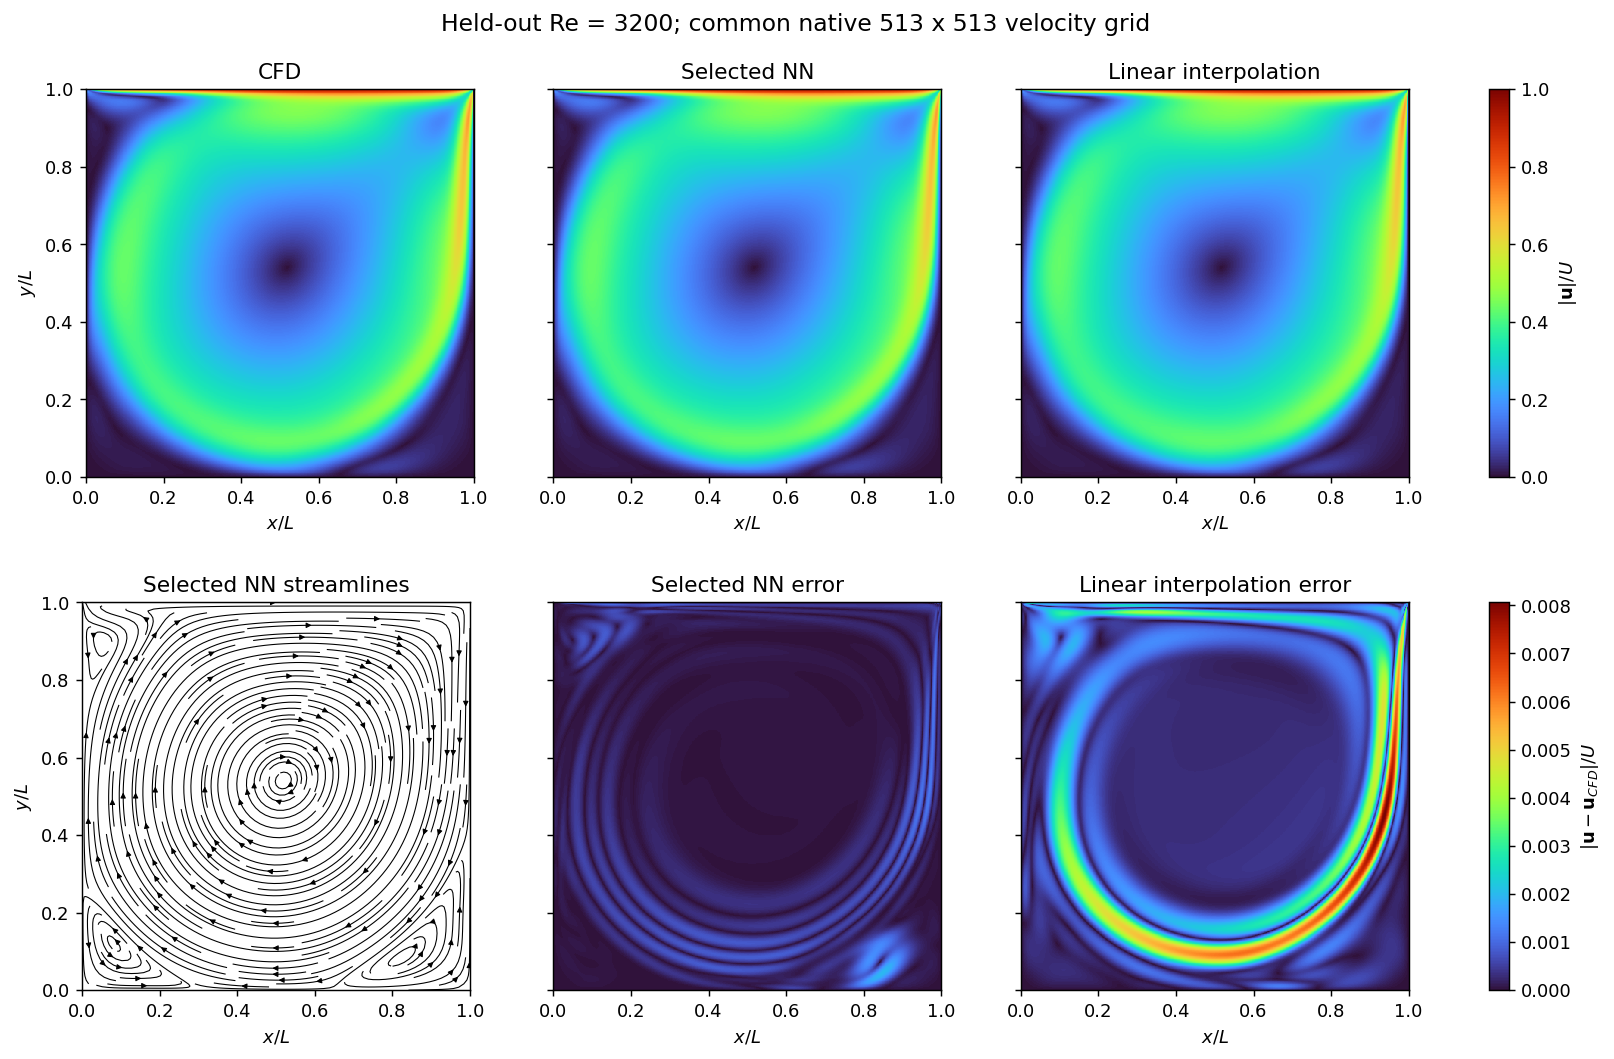

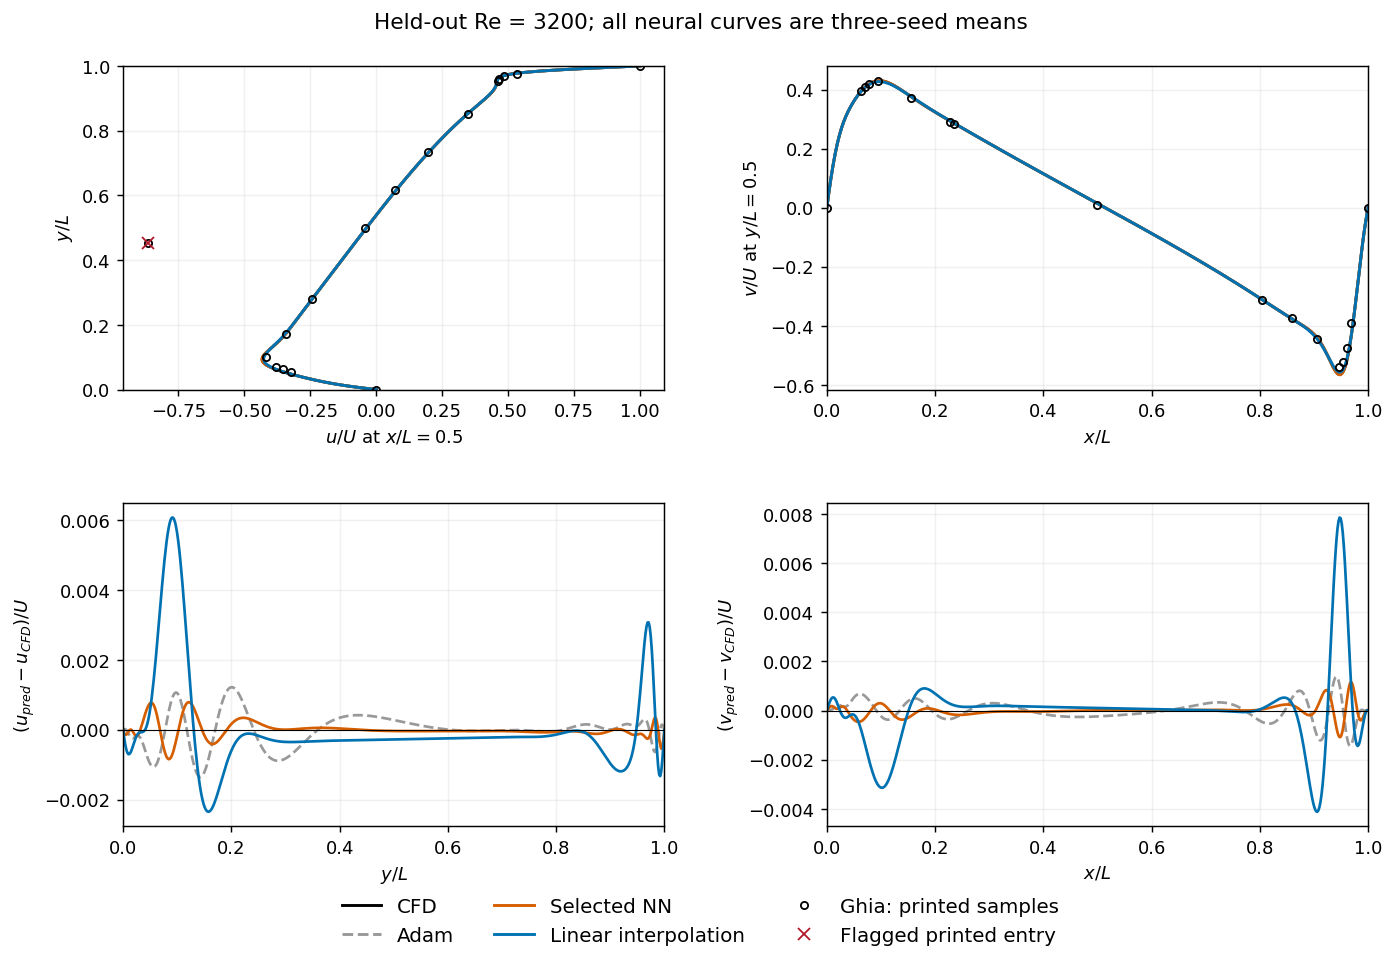

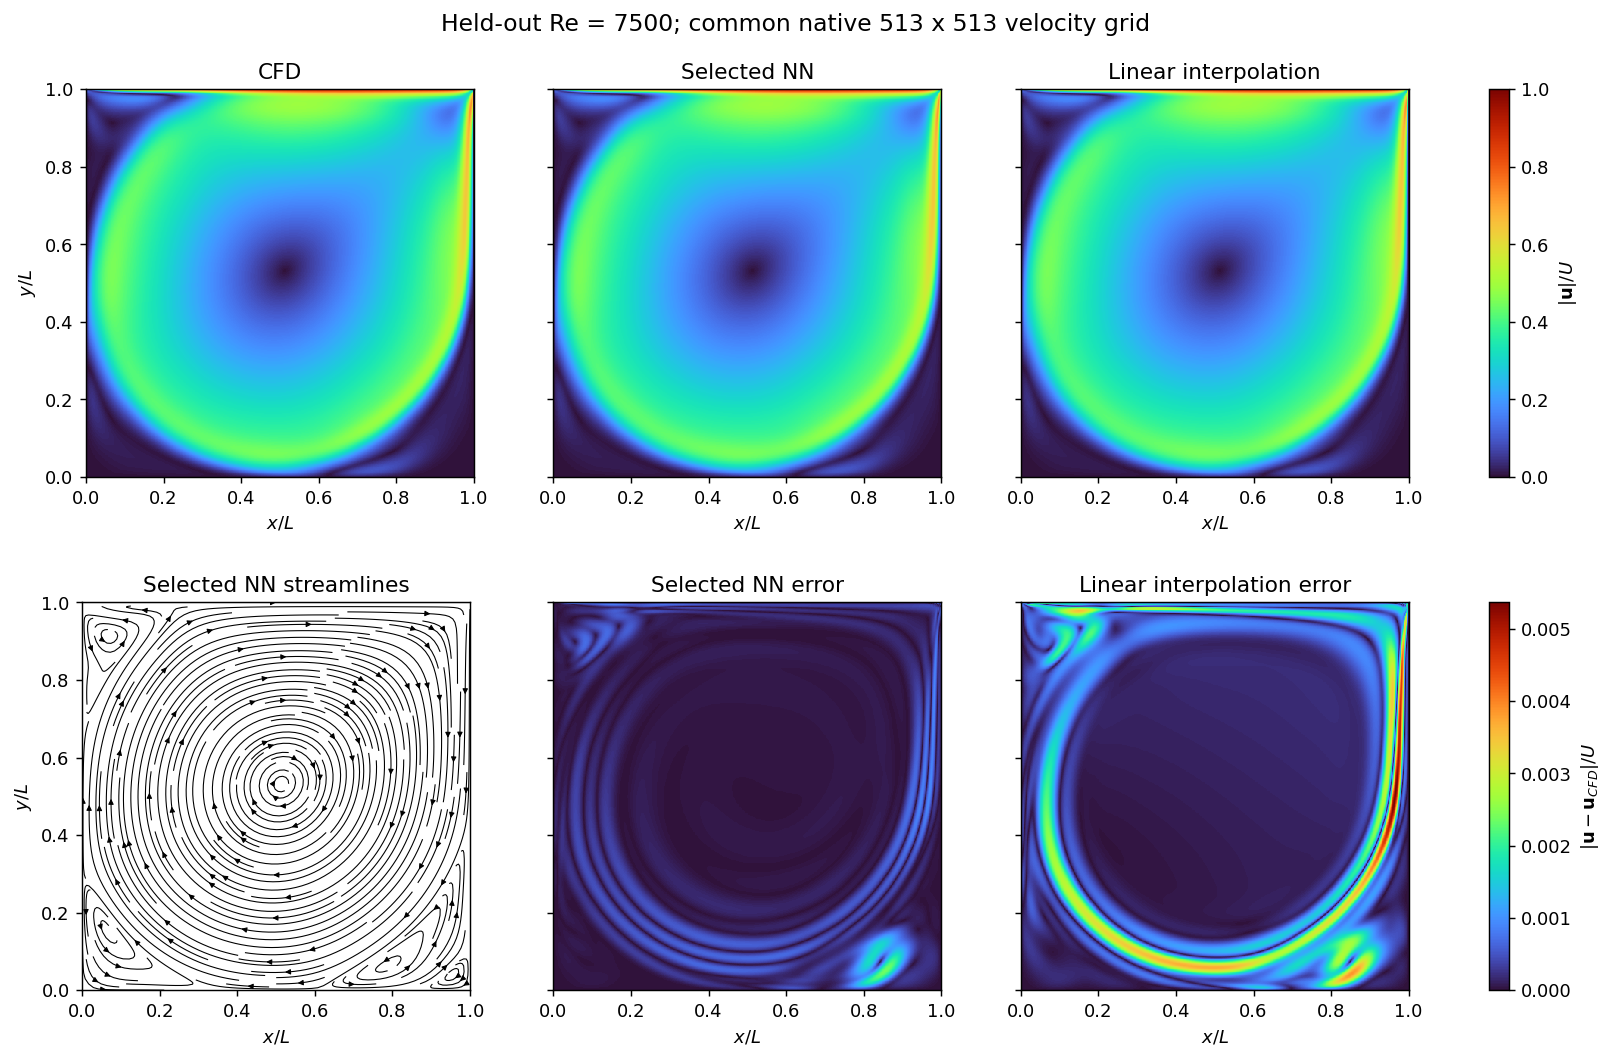

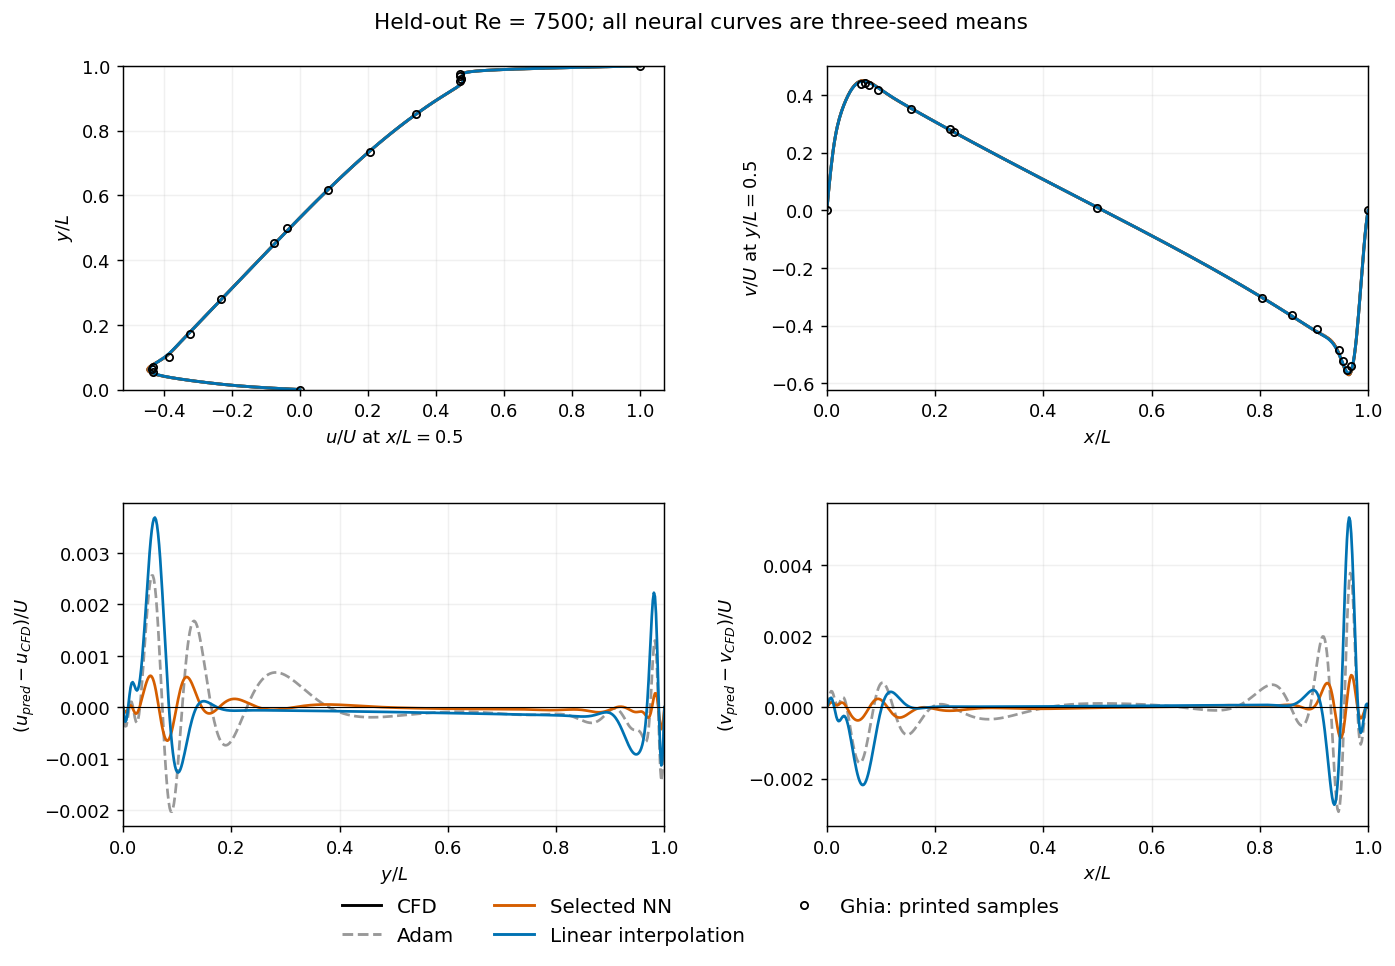

In [4]:
test_scores = pd.read_csv(OUT/'test_scores.csv')
reported = test_scores[test_scores.method.isin([
    'selected_three_seed_mean','linear_in_Re','linear_in_log_Re'])]
display(reported[['method','Re','relative_l2','rmse_U','linf_U',
                  'u_relative_l2','v_relative_l2']])
for reynolds, fields in cases.items():
    evidence.plot_fields(fields,reynolds)
    plt.show()
    evidence.plot_profiles(fields,reynolds)
    plt.show()

## 5. Physical constraints and numerical limits

Linear combinations preserve matched wall velocities and discrete continuity.
They generally do not satisfy nonlinear Navier-Stokes at a new Re.
Re-evaluate the vorticity-transport, Poisson, wall and continuity defects below.

Also compare surrogate error with 256-to-512 mesh sensitivity on common native
points. The mesh difference is not an exact-error bound or confidence interval.
It can exceed neural error; excellent agreement with one discretization does
not establish physical accuracy. A steady root does not establish stability.

In [5]:
physical = pd.DataFrame(evidence.diagnostics(cases))
display(physical[['Re','method','relative_velocity_l2','steady_vorticity_linf',
                  'poisson_linf','continuity_linf','wall_linf']])
mesh = pd.read_csv(ROOT/'results/cavity_highre_ghia/mesh_sensitivity.csv')
display(mesh[(mesh.cells==256)&mesh.Re.isin(op.TEST)][[
    'Re','cells','reference_cells','velocity_relative_l2','u_linf_U','v_linf_U']])

,Re,method,relative_velocity_l2,steady_vorticity_linf,poisson_linf,continuity_linf,wall_linf
0,3200,CFD,0.000000,4.920011e-10,3.244716e-11,2.842171e-14,0.000000e+00
1,3200,Selected NN,0.000951,7.975351e+02,7.508083e-11,1.419975e-13,6.912160e-11
2,3200,Linear interpolation,0.005394,2.060406e+03,5.746559e-11,1.274536e-13,4.251888e-11
3,3200,Adam,0.001463,5.553663e+02,7.453549e-11,1.221800e-13,4.547474e-12
4,7500,CFD,0.000000,7.270160e-09,3.140821e-11,2.842171e-14,0.000000e+00
5,7500,Selected NN,0.000844,2.961648e+02,5.707568e-11,1.211808e-13,4.331469e-11
6,7500,Linear interpolation,0.003139,1.329394e+03,5.152900e-11,1.194600e-13,4.547474e-12
7,7500,Adam,0.002679,1.093627e+03,4.620393e-11,1.336153e-13,3.865352e-12


,Re,cells,reference_cells,velocity_relative_l2,u_linf_U,v_linf_U
15,3200,256,512,0.020252,0.011273,0.015020
25,7500,256,512,0.047195,0.026665,0.036192


## 6. Engineering exercises and required deliverables

**A — Optimizer/depth/weighting.** Using Section 2, report mean and seed range
at each validation Re for all five configurations. Compare Adam versus hybrid
at fixed depth, two versus five layers, and global versus per-mode scaling.
Identify improvements and deterioration, with parameter counts and evaluation
budgets. Do not select the model using Section 4 tests.

**B — Training information.** Explain the 3.2510% projection floor in Section 3.
Compare first-round and current validation errors after adding Re=500 and 750.
The training information changes; do not attribute this effect to optimization.

**C — Physical error.** For each test Re, report vector and component relative
L2 errors, plus the maximum signed centreline discrepancy and its location.
Compare the selected three-seed mean with both baselines. Report wins and
losses. Supply signed u/v profile plots, not bar charts.

**D — Numerical limits.** From Section 5 compare surrogate error with mesh
sensitivity, and wall/continuity errors with nonlinear residuals. Explain
why none of exact continuity, a small supervised loss or a small mesh
difference alone proves an accurate physical solution.

**E — Deliberate CPU training.** Enable the cell below and change one setting:
depth, width, scaling or Adam budget. Train only on the training POD coefficients
and score validation cases. Record runtime and parameter count. Published test
results are already visible, so further test-based experimentation is exploratory.
Predeclare fresh withheld cases for a new blind research claim.

Submit one CSV for A-D, the two signed physical-profile comparisons, and a short
interpretation separating representation, optimization and discretization errors.
Record software version and model/data hashes.

In [6]:
RUN_NEW_CPU_EXPERIMENT = False
if RUN_NEW_CPU_EXPERIMENT:
    trunk = dict(np.load(OUT/'trunk.npz',allow_pickle=False))
    trial = op.Config('student_trial',depth=3,width=24,optimizer='hybrid',
                      scaling='global',evaluations=2000,adam_evaluations=600)
    model = op.fit(trial,7,trunk['train_coefficients'])
    prediction = op.reconstruct(trunk,op.predict_coefficients(model,op.VALIDATION))
    rows = []
    for j,reynolds in enumerate(op.VALIDATION):
        data = np.load(ROOT/f'results/cavity_highre_ghia/n512/re{reynolds}.npz',allow_pickle=False)
        truth = np.r_[data['u'].ravel(),data['v'].ravel()]
        rows.append({'Re':reynolds,**op.velocity_error(prediction[j],truth)})
    display(pd.DataFrame(rows))
    print('Parameters:',len(model['theta']),'seconds:',model['training_seconds'])
else:
    print('No training requested; frozen results remain unchanged.')

No training requested; frozen results remain unchanged.
